# Explainability Layer: Phishing Email Models (local GPU)

Explains the saved models without retraining. Written for a local NVIDIA GPU (tested settings sized for 6 GB, e.g. RTX 3050).

| Model | Method | What it shows |
|---|---|---|
| A. TF-IDF + LogReg | Exact word contributions (weight x word score) | Which words pushed the score, exactly |
| C. Corrected (fine-tuned BERT) | Integrated Gradients | Which words pushed the score toward phishing or safe |
| B / D. Paper architecture | Not explained | Its attention gives 100% to one input, so there is nothing to explain |

## One-time setup (terminal)

```
python -m venv xai-env
xai-env\Scripts\activate            (Windows)   |   source xai-env/bin/activate   (Linux/Mac)
pip install torch --index-url https://download.pytorch.org/whl/cu124
pip install "transformers>=4.44" "scikit-learn==1.6.1" pandas numpy matplotlib jupyter
```

- `scikit-learn==1.6.1` must match the version used in training, or Model A may fail to load.
- Check the GPU: `python -c "import torch; print(torch.cuda.is_available(), torch.cuda.get_device_name(0))"`

## Folder layout

Unzip `phishing_artifacts.zip` next to this notebook and put the dataset in it:

```
this_notebook.ipynb
phishing_artifacts/
    Phishing_Email.csv                 (required, the Kaggle dataset)
    A_tfidf_logreg.joblib              (required)
    C_corrected_finetuned_full.pt      (required)
    tokenizer/                         (optional, makes it fully offline)
    config_and_versions.json           (optional)
    test_predictions.csv               (optional, enables the integrity check)
```
If your files are elsewhere, change `ART` in the setup cell.

## Step 1: Setup

In [1]:
import os
# Stop transformers from importing TensorFlow / JAX (a broken TF install crashes the import)
os.environ["USE_TF"] = "0"; os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["USE_TORCH"] = "1"; os.environ["USE_FLAX"] = "0"; os.environ["USE_JAX"] = "0"

import os, re, json, html, shutil, random, time, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
import joblib
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ON_GPU = DEVICE.type == "cuda"
print("Device:", DEVICE)

# Same settings as training. Overwritten by config_and_versions.json if you upload it.
CFG = {"bert_name": "bert-base-uncased", "max_len": 128, "n_heads": 8, "cnn_filters": 128,
       "cnn_kernel": 5, "gru_units": 64, "dropout": 0.3, "test_size": 0.15, "val_size": 0.15}

# Fewer emails on CPU so it finishes in a few minutes
# Sized for a 6 GB GPU. Lower IG_BATCH to 4 if you get "CUDA out of memory".
N_PER_CLASS = 20 if ON_GPU else 10      # sample size per class for IG
IG_STEPS    = 64 if ON_GPU else 32      # more steps = more accurate IG
IG_BATCH    = 8  if ON_GPU else 8

if ON_GPU:
    print("GPU:", torch.cuda.get_device_name(0), f"| {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("No GPU found. It will run on CPU (slower). Check your CUDA install of torch.")

ART = os.path.abspath("phishing_artifacts")      # change this if your files are elsewhere
OUT = os.path.abspath("xai_outputs")
os.makedirs(OUT, exist_ok=True)

def need(name):
    p = os.path.join(ART, name)
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing {p}")
    return p

def maybe(name):
    p = os.path.join(ART, name)
    return p if os.path.exists(p) else None

DATA_PATH = need("Phishing_Email.csv")
A_PATH    = need("A_tfidf_logreg.joblib")
C_PATH    = need("C_corrected_finetuned_full.pt")
CFG_PATH  = maybe("config_and_versions.json")
PRED_PATH = maybe("test_predictions.csv")
TOK_DIR   = maybe("tokenizer")
for k, v in [("config", CFG_PATH), ("test_predictions", PRED_PATH), ("tokenizer", TOK_DIR)]:
    print(f"optional {k:<17}: {'found' if v else 'not found'}")

if CFG_PATH:
    saved = json.load(open(CFG_PATH))
    CFG.update({k: v for k, v in saved.get("cfg", {}).items() if k in CFG})
    print("Training versions:", saved.get("versions"))
print("CFG:", CFG)

from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(TOK_DIR or CFG["bert_name"])   # downloads once if no local folder
print("Tokenizer:", "local folder" if TOK_DIR else "downloaded", "| vocab size", tokenizer.vocab_size)

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU | 6.4 GB
optional config           : found
optional test_predictions : found
optional tokenizer        : found
Training versions: {'python': '3.13.15', 'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'tokenizers': '0.23.2', 'scikit-learn': '1.6.1', 'pandas': '2.2.3'}
CFG: {'bert_name': 'bert-base-uncased', 'max_len': 128, 'n_heads': 8, 'cnn_filters': 128, 'cnn_kernel': 5, 'gru_units': 64, 'dropout': 0.3, 'test_size': 0.15, 'val_size': 0.15}
Tokenizer: local folder | vocab size 30522


## Step 3: Rebuild the same test set

Same cleaning, same split, same seed as the training notebook.

In [2]:
DF = pd.read_csv(DATA_PATH)
TEXT_COL  = [c for c in DF.columns if "text" in c.lower()][0]
LABEL_COL = [c for c in DF.columns if "type" in c.lower() or "label" in c.lower()][0]
df = DF.dropna(subset=[TEXT_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str)
df = df[~df[TEXT_COL].str.strip().str.lower().isin(["", "empty", "nan", "none"])]
df = df.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)
df["label"] = df[LABEL_COL].apply(lambda v: 1 if "phish" in str(v).lower() else 0)

X, y = df[TEXT_COL].values, df["label"].values
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=CFG["test_size"], stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=CFG["val_size"] / (1 - CFG["test_size"]), stratify=y_tmp, random_state=SEED)
print(f"train={len(X_train)} val={len(X_val)} test={len(X_test)} | test phishing={y_test.mean():.1%}")

train=12273 val=2631 test=2631 | test phishing=37.4%


## Step 4: Load models

In [3]:
from transformers import BertConfig, BertModel

# Model A
bundle = joblib.load(A_PATH)
tfidf, clf = bundle["tfidf"], bundle["clf"]
VOCAB = tfidf.vocabulary_
FEAT = np.array(tfidf.get_feature_names_out())
COEF = clf.coef_[0]
print("Model A loaded:", len(VOCAB), "features")

# Model C: same class as training. Built from config only, then the saved weights are loaded.
class BCGMHeadAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.bert = BertModel(BertConfig())    # BertConfig() defaults = bert-base-uncased, no download needed
        H = self.bert.config.hidden_size
        self.bn    = nn.BatchNorm1d(H)
        self.mha   = nn.MultiheadAttention(H, cfg["n_heads"], batch_first=True, dropout=cfg["dropout"])
        self.lnorm = nn.LayerNorm(H)
        self.conv  = nn.Conv1d(H, cfg["cnn_filters"], cfg["cnn_kernel"], padding="same")
        self.relu  = nn.ReLU()
        self.pool  = nn.MaxPool1d(2)
        self.gru   = nn.GRU(cfg["cnn_filters"], cfg["gru_units"], batch_first=True, bidirectional=True)
        self.drop  = nn.Dropout(cfg["dropout"])
        self.fc1   = nn.Linear(2 * cfg["gru_units"], 64)
        self.fc2   = nn.Linear(64, 1)

    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None):
        # inputs_embeds lets Integrated Gradients feed word vectors directly
        x = self.bert(input_ids=input_ids, inputs_embeds=inputs_embeds, attention_mask=attention_mask).last_hidden_state
        x = self.bn(x.transpose(1, 2)).transpose(1, 2)
        a, _ = self.mha(x, x, x, key_padding_mask=(attention_mask == 0))
        x = self.lnorm(x + a)
        x = self.pool(self.relu(self.conv(x.transpose(1, 2)))).transpose(1, 2)
        _, h = self.gru(x)
        h = self.drop(torch.cat([h[0], h[1]], dim=1))
        return self.fc2(self.relu(self.fc1(h))).squeeze(1)

model_c = BCGMHeadAttention(CFG)
state = torch.load(C_PATH, map_location="cpu")
missing, unexpected = model_c.load_state_dict(state, strict=False)
bad = [k for k in list(missing) + list(unexpected) if not k.endswith("position_ids")]
assert not bad, f"Weights do not match the model: {bad[:10]}"
model_c.to(DEVICE).eval()
for p in model_c.parameters():
    p.requires_grad_(False)          # we only need gradients for the input words
del state
print("Model C loaded")

def prob_a(texts):
    return clf.predict_proba(tfidf.transform(list(texts)))[:, 1]

@torch.no_grad()
def prob_c(texts, bs=32):
    out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer([str(t) for t in texts[i:i + bs]], truncation=True, padding="max_length",
                        max_length=CFG["max_len"], return_tensors="pt").to(DEVICE)
        out.append(torch.sigmoid(model_c(enc["input_ids"], enc["attention_mask"])).float().cpu().numpy())
    return np.concatenate(out)

W1013 19:02:42.067000 24012 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1013 19:02:42.226000 24012 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Model A loaded: 50000 features
Model C loaded


In [4]:
# Integrity check (only if test_predictions.csv was uploaded)
PRED = pd.read_csv(PRED_PATH) if PRED_PATH else None
if PRED is not None:
    same_labels = len(PRED) == len(y_test) and (PRED["y_true"].values == y_test).all()
    print("Same test labels as training run:", same_labels)
    if same_labels:
        da = np.abs(prob_a(X_test) - PRED["prob_a"].values).max()
        idx = np.arange(min(64, len(X_test)))
        dc = np.abs(prob_c(X_test[idx]) - PRED["prob_c"].values[idx]).max()
        print(f"Model A max prob difference: {da:.2e}  (should be about 0)")
        print(f"Model C max prob difference on 64 emails: {dc:.2e}  (small, under 1e-3, is fine)")
        if dc > 1e-2:
            print("WARNING: Model C does not reproduce the saved predictions. Check CFG and the .pt file.")
else:
    print("Skipped (no test_predictions.csv). Explanations still work.")

Same test labels as training run: True
Model A max prob difference: 3.33e-16  (should be about 0)
Model C max prob difference on 64 emails: 4.79e-06  (small, under 1e-3, is fine)


## Step 5: Explain Model A (exact)

For a linear model the score is a sum: each word's TF-IDF value times its learned weight, plus a constant. So each word's share is exact, not estimated.
Red = pushes toward phishing. Blue = pushes toward safe.

  safe_word  safe_weight phish_word  phish_weight
      enron       -6.443      click         4.305
     thanks       -4.306       free         3.816
       2002       -4.212     remove         3.606
   language       -4.064      money         3.422
      wrote       -3.965       2005         3.344
 university       -3.685      email         3.148
linguistics       -3.453     online         2.883
   attached       -3.350       2004         2.839
       2001       -3.316       save         2.661
      vince       -3.193       site         2.653
        edu       -3.118      offer         2.642
       2000       -2.946       life         2.608
        url       -2.746       best         2.401
   url http       -2.737       want         2.388
     louise       -2.629        low         2.360
       date       -2.576    removed         2.353
    english       -2.531      hello         2.345
 conference       -2.365      reply         2.336
  questions       -2.354   software         2.327


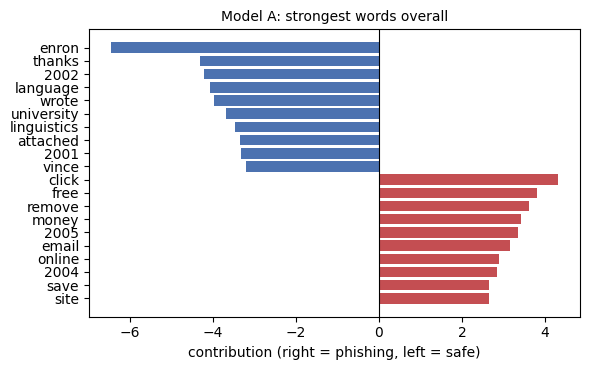

In [5]:
TOKEN_RE = re.compile(r"(?u)\b\w\w+\b")       # same word pattern TF-IDF uses
MAX_SHOW = 150                                  # words shown in the highlight

def explain_a(text):
    x = tfidf.transform([text])
    contrib = dict(zip(x.indices, x.data * COEF[x.indices]))
    logit = sum(contrib.values()) + clf.intercept_[0]
    prob = 1 / (1 + np.exp(-logit))
    words = TOKEN_RE.findall(text.lower())[:MAX_SHOW]
    scores = [contrib.get(VOCAB.get(w, -1), 0.0) for w in words]
    top = sorted(((FEAT[i], c) for i, c in contrib.items()), key=lambda t: -abs(t[1]))[:10]   # includes 2-word phrases
    return {"prob": prob, "words": words, "scores": scores, "top": top, "contrib": contrib}

def highlight(words, scores, title):
    m = max([abs(s) for s in scores] + [1e-9])
    spans = []
    for w, s in zip(words, scores):
        a = min(abs(s) / m, 1) * 0.85
        bg = f"rgba(220,40,40,{a:.2f})" if s > 0 else f"rgba(40,90,220,{a:.2f})"
        spans.append(f'<span style="background:{bg};padding:1px 3px;border-radius:3px">{html.escape(w)}</span>')
    return (f"<div style='font-family:sans-serif;line-height:2;margin:10px 0'><b>{html.escape(title)}</b><br>"
            + " ".join(spans) + "</div>")

def bar_top(top, title, fname):
    names = [t[0] for t in top][::-1]; vals = [t[1] for t in top][::-1]
    plt.figure(figsize=(6, 3.8))
    plt.barh(names, vals, color=["#C44E52" if v > 0 else "#4C72B0" for v in vals])
    plt.axvline(0, color="black", lw=0.8); plt.title(title, fontsize=10)
    plt.xlabel("contribution (right = phishing, left = safe)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT, fname), dpi=200); plt.show()

# Global view: words with the largest weights overall
order = np.argsort(COEF)
GLOBAL_A = pd.DataFrame({"safe_word": FEAT[order[:20]], "safe_weight": COEF[order[:20]].round(3),
                         "phish_word": FEAT[order[::-1][:20]], "phish_weight": COEF[order[::-1][:20]].round(3)})
print(GLOBAL_A.to_string(index=False))
GLOBAL_A.to_csv(os.path.join(OUT, "global_A_top_words.csv"), index=False)
bar_top([(FEAT[i], COEF[i]) for i in list(order[:10]) + list(order[::-1][:10])],
        "Model A: strongest words overall", "global_A.png")

## Step 6: Explain Model C (Integrated Gradients)

IG starts from a blank email (all words replaced by padding) and slowly fades the real words in. It adds up how much each word moved the score along the way.
**Completeness check:** the word scores should add up to (score of real email minus score of blank email). A small gap means the explanation is trustworthy.
Only the first 128 tokens are explained, because the model never sees the rest.

In [6]:
SPECIAL = set(tokenizer.all_special_ids)
EMB = model_c.bert.embeddings.word_embeddings

def ig_explain(text, steps=IG_STEPS, batch=IG_BATCH):
    enc = tokenizer(text, truncation=True, padding="max_length", max_length=CFG["max_len"], return_tensors="pt")
    ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
    keep_special = torch.tensor([t in SPECIAL for t in ids[0].tolist()], device=DEVICE)
    base_ids = torch.where(keep_special, ids[0], torch.full_like(ids[0], tokenizer.pad_token_id)).unsqueeze(0)
    with torch.no_grad():
        x, x0 = EMB(ids), EMB(base_ids)
    grads = torch.zeros_like(x)
    alphas = (torch.arange(steps, dtype=torch.float32) + 0.5) / steps        # midpoint rule
    with torch.backends.cudnn.flags(enabled=False):                          # GRU backward in eval mode
        for chunk in alphas.split(batch):
            xs = (x0 + chunk.view(-1, 1, 1).to(DEVICE) * (x - x0)).requires_grad_(True)
            out = model_c(inputs_embeds=xs, attention_mask=mask.expand(len(chunk), -1))
            g, = torch.autograd.grad(out.sum(), xs)
            grads += g.sum(0, keepdim=True)
    attr = ((x - x0) * grads / steps).sum(-1)[0].detach().cpu().numpy()
    with torch.no_grad():
        f_x = model_c(inputs_embeds=x, attention_mask=mask).item()
        f_0 = model_c(inputs_embeds=x0, attention_mask=mask).item()
    # merge word pieces ("phish", "##ing") into whole words
    toks = tokenizer.convert_ids_to_tokens(ids[0].tolist())
    words, scores = [], []
    for t, a, i, m in zip(toks, attr, ids[0].tolist(), mask[0].tolist()):
        if m == 0 or i in SPECIAL:
            continue
        if t.startswith("##") and words:
            words[-1] += t[2:]; scores[-1] += a
        else:
            words.append(t); scores.append(float(a))
    gap = abs(sum(scores) - (f_x - f_0)) / (abs(f_x - f_0) + 1e-9)
    return {"prob": 1 / (1 + np.exp(-f_x)), "words": words, "scores": scores, "gap": gap,
            "truncated": int(mask.sum()) >= CFG["max_len"]}

def top_words(words, scores, k=10):
    agg = {}
    for w, s in zip(words, scores):
        agg[w] = agg.get(w, 0.0) + s
    return sorted(agg.items(), key=lambda t: -abs(t[1]))[:k]

t0 = time.time(); _ = ig_explain(X_test[0])
print(f"One IG explanation took {time.time() - t0:.1f} s on {DEVICE}. Completeness gap: {_['gap']:.1%}")

One IG explanation took 1.4 s on cuda. Completeness gap: 58.7%


In [7]:
# Pick test emails to explain: N_PER_CLASS of each class, plus Model C's mistakes if known
rng = np.random.default_rng(SEED)
pick = list(rng.choice(np.where(y_test == 1)[0], N_PER_CLASS, replace=False)) + \
       list(rng.choice(np.where(y_test == 0)[0], N_PER_CLASS, replace=False))
if PRED is not None and len(PRED) == len(y_test):
    wrong = np.where((PRED["prob_c"].values >= .5).astype(int) != y_test)[0]
    pick += [i for i in wrong[:4] if i not in pick]
    print(f"Model C mistakes in test set: {len(wrong)} (adding up to 4)")

RESULTS = []
t0 = time.time()
for n, i in enumerate(pick):
    text = str(X_test[i])
    ea, ec = explain_a(text), ig_explain(text)
    RESULTS.append({"idx": int(i), "label": int(y_test[i]), "text": text, "A": ea, "C": ec})
    print(f"  {n + 1}/{len(pick)} explained", end="\r")
print(f"\nDone in {(time.time() - t0) / 60:.1f} min")
gaps = [r["C"]["gap"] for r in RESULTS]
print(f"IG completeness gap: median {np.median(gaps):.1%}, max {np.max(gaps):.1%}  (under about 5% is good)")

Model C mistakes in test set: 38 (adding up to 4)
  44/44 explained
Done in 0.8 min
IG completeness gap: median 6.0%, max 162.4%  (under about 5% is good)


In [14]:
# Re-run IG with more steps for emails whose completeness gap is too large
@torch.no_grad()
def real_and_blank_logits(text):
    enc = tokenizer(text, truncation=True, padding="max_length", max_length=CFG["max_len"], return_tensors="pt")
    ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
    keep = torch.tensor([t in SPECIAL for t in ids[0].tolist()], device=DEVICE)
    base = torch.where(keep, ids[0], torch.full_like(ids[0], tokenizer.pad_token_id)).unsqueeze(0)
    return model_c(ids, mask).item(), model_c(base, mask).item()

rows = []
t0 = time.time()
for r in RESULTS:
    fx, f0 = real_and_blank_logits(r["text"])
    delta, steps = fx - f0, IG_STEPS
    # A percentage gap only means something when real and blank scores differ clearly
    while r["C"]["gap"] > 0.05 and abs(delta) > 0.5 and steps < 512:
        steps *= 2
        r["C"] = ig_explain(r["text"], steps=steps)
    rows.append({"idx": r["idx"], "steps": steps, "score_change": round(delta, 3),
                 "gap_pct": round(100 * r["C"]["gap"], 1),
                 "abs_gap": round(r["C"]["gap"] * abs(delta), 3)})
GAPS = pd.DataFrame(rows)
print(f"Done in {(time.time() - t0) / 60:.1f} min")
print(GAPS.sort_values("gap_pct", ascending=False).head(10).to_string(index=False))

big = GAPS[GAPS.score_change.abs() > 0.5]
print(f"\nEmails with a clear score change ({len(big)}): median gap {big.gap_pct.median():.1f}%, max {big.gap_pct.max():.1f}%")
print(f"Emails with a tiny score change ({len(GAPS) - len(big)}): judged by absolute gap, max {GAPS.abs_gap.max():.3f}")
GAPS.to_csv(os.path.join(OUT, "ig_completeness.csv"), index=False)

Done in 2.9 min
 idx  steps  score_change   gap_pct  abs_gap
 161    512        -1.448 47.700001    0.691
1352     64        -0.375  9.100000    0.034
 173    128       -12.717  4.700000    0.602
1658    256       -12.582  4.700000    0.594
1976     64         0.063  4.300000    0.003
1450    128       -12.636  3.900000    0.487
 505    512       -12.750  3.500000    0.445
1833    512       -12.670  3.500000    0.440
  17     64        -9.631  3.500000    0.340
2044     64       -12.726  3.200000    0.401

Emails with a clear score change (27): median gap 1.9%, max 47.7%
Emails with a tiny score change (17): judged by absolute gap, max 0.691


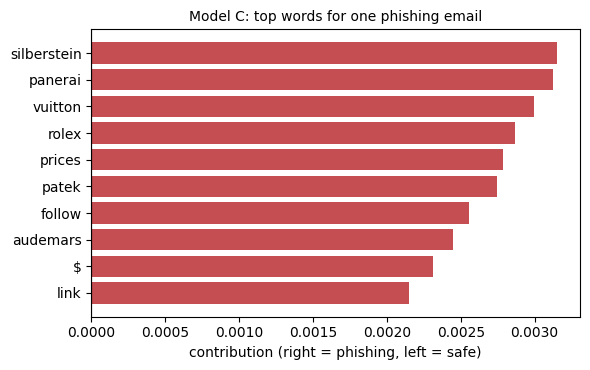

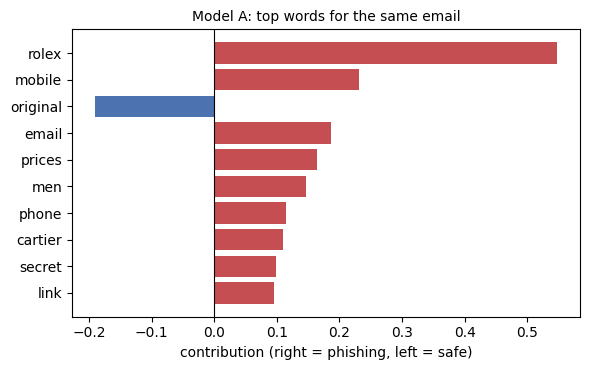

In [8]:
# Show examples: 2 phishing, 2 safe, and Model C mistakes
HTML_PARTS = []
def show(r, tag):
    lab = "PHISHING" if r["label"] else "SAFE"
    a, c = r["A"], r["C"]
    head = f"[{tag}] true={lab} | A p(phish)={a['prob']:.3f} | C p(phish)={c['prob']:.3f}"
    part = highlight(a["words"], a["scores"], head + " | Model A") + \
           highlight(c["words"], c["scores"], head + " | Model C" + (" (truncated at 128 tokens)" if c["truncated"] else ""))
    HTML_PARTS.append(part); display(HTML(part))

phish = [r for r in RESULTS if r["label"] == 1][:2]
safe = [r for r in RESULTS if r["label"] == 0][:2]
errors = [r for r in RESULTS if (r["C"]["prob"] >= .5) != bool(r["label"])][:4]
for k, r in enumerate(phish): show(r, f"phish {k + 1}")
for k, r in enumerate(safe): show(r, f"safe {k + 1}")
for k, r in enumerate(errors): show(r, f"C mistake {k + 1}")
if not errors: print("No Model C mistakes in this sample.")

r = phish[0]
bar_top(top_words(r["C"]["words"], r["C"]["scores"]), "Model C: top words for one phishing email", "example_C_phish.png")
bar_top(r["A"]["top"], "Model A: top words for the same email", "example_A_phish.png")

## Step 7: Faithfulness (deletion test)

If the highlighted words really drive the decision, deleting the top 5 should hurt the model's confidence much more than deleting 5 random words.

Average drop in confidence for the predicted class:
       drop_top5  drop_random5  top_beats_random_%
model                                             
A         0.1581        0.0032            100.0000
C         0.1427        0.0134             63.6364
Faithful explanation: drop_top5 clearly larger than drop_random5.


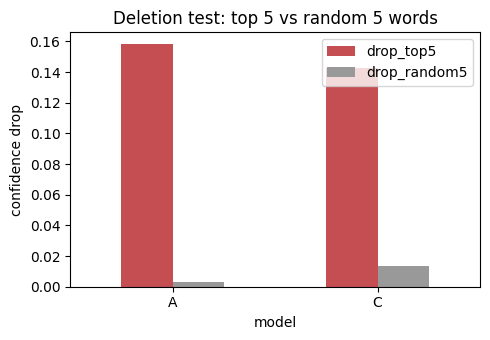

In [9]:
K, RANDOM_TRIALS = 5, 3

def deletion_c(r):
    words, scores = r["C"]["words"], np.array(r["C"]["scores"])
    if len(words) <= K: return None
    sign = 1 if r["C"]["prob"] >= .5 else -1                    # words supporting the predicted class
    full = " ".join(words)
    top = set(np.argsort(-sign * scores)[:K])
    texts = [full, " ".join(w for j, w in enumerate(words) if j not in top)]
    for _ in range(RANDOM_TRIALS):
        rnd = set(rng.choice(len(words), K, replace=False))
        texts.append(" ".join(w for j, w in enumerate(words) if j not in rnd))
    p = prob_c(texts)
    conf = p if sign == 1 else 1 - p
    return conf[0] - conf[1], np.mean(conf[0] - conf[2:])

def deletion_a(r):
    text = r["text"].lower()
    words = sorted(set(TOKEN_RE.findall(text)))
    sc = {w: r["A"]["contrib"].get(VOCAB.get(w, -1), 0.0) for w in words}
    if len(words) <= K: return None
    sign = 1 if r["A"]["prob"] >= .5 else -1
    top = sorted(words, key=lambda w: -sign * sc[w])[:K]
    def drop(ws): return TOKEN_RE.sub(lambda m: "" if m.group(0) in ws else m.group(0), text)
    texts = [text, drop(set(top))] + [drop(set(rng.choice(words, K, replace=False))) for _ in range(RANDOM_TRIALS)]
    p = prob_a(texts); conf = p if sign == 1 else 1 - p
    return conf[0] - conf[1], np.mean(conf[0] - conf[2:])

rows = []
for r in RESULTS:
    for name, fn in [("A", deletion_a), ("C", deletion_c)]:
        res = fn(r)
        if res: rows.append({"model": name, "idx": r["idx"], "drop_top5": res[0], "drop_random5": res[1]})
DEL = pd.DataFrame(rows)
DEL_SUM = DEL.groupby("model")[["drop_top5", "drop_random5"]].mean()
DEL_SUM["top_beats_random_%"] = DEL.assign(w=DEL.drop_top5 > DEL.drop_random5).groupby("model").w.mean() * 100
print("Average drop in confidence for the predicted class:")
print(DEL_SUM.round(4))
print("Faithful explanation: drop_top5 clearly larger than drop_random5.")
DEL.to_csv(os.path.join(OUT, "deletion_test.csv"), index=False)

DEL_SUM[["drop_top5", "drop_random5"]].plot(kind="bar", figsize=(5, 3.5), rot=0, color=["#C44E52", "#999999"])
plt.title("Deletion test: top 5 vs random 5 words"); plt.ylabel("confidence drop")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "deletion_test.png"), dpi=200); plt.show()

## Step 8: Shortcut check

A shortcut is a word that only appears in one class because of where the emails came from (a company name, a person's name, a mailing list), not because it signals phishing.
If the top "safe" words are names and company terms, the models learned the source, and accuracy will drop on emails from other places.

In [10]:
# 1) Words that almost only appear in one class in the training data
cv = CountVectorizer(binary=True, min_df=30)
M = cv.fit_transform(X_train)
vocab = np.array(cv.get_feature_names_out())
n_ph = np.asarray(M[y_train == 1].sum(0)).ravel(); n_sf = np.asarray(M[y_train == 0].sum(0)).ravel()
purity = np.maximum(n_ph, n_sf) / (n_ph + n_sf)
mask = (purity >= 0.99) & ~np.isin(vocab, list(ENGLISH_STOP_WORDS))
SHORT = pd.DataFrame({"word": vocab[mask], "class": np.where(n_ph[mask] > n_sf[mask], "phishing", "safe"),
                      "emails": (n_ph + n_sf)[mask], "purity": purity[mask].round(4)}).sort_values("emails", ascending=False)
print("Words found in 99%+ one class (top 30 by frequency):")
print(SHORT.head(30).to_string(index=False))
SHORT.to_csv(os.path.join(OUT, "one_class_words.csv"), index=False)

# 2) How many of Model A's strongest words are one-class words?
one_class = set(SHORT.word)
for side, words in [("safe", FEAT[order[:30]]), ("phishing", FEAT[order[::-1][:30]])]:
    uni = [w for w in words if " " not in w]
    print(f"Model A top-30 {side} words that are one-class words: {sum(w in one_class for w in uni)}/{len(uni)}")

# 3) Model C global view: average IG score per word over the explained emails
agg = {}
for r in RESULTS:
    for w, s in top_words(r["C"]["words"], r["C"]["scores"], k=10 ** 6):
        agg.setdefault(w, []).append(s)
GLOBAL_C = pd.DataFrame([{"word": w, "mean_score": np.mean(v), "emails": len(v)} for w, v in agg.items() if len(v) >= 3],
                        columns=["word", "mean_score", "emails"])
GLOBAL_C = GLOBAL_C[~GLOBAL_C.word.isin(ENGLISH_STOP_WORDS) & (GLOBAL_C.word.str.len() > 2)]
GLOBAL_C["one_class_word"] = GLOBAL_C.word.isin(one_class)
print("\nModel C, words pushing to PHISHING (in 3+ explained emails):")
print(GLOBAL_C.nlargest(15, "mean_score").round(3).to_string(index=False))
print("\nModel C, words pushing to SAFE:")
print(GLOBAL_C.nsmallest(15, "mean_score").round(3).to_string(index=False))
print(f"\nBased on only {len(RESULTS)} emails, so treat Model C's global list as indicative.")
GLOBAL_C.to_csv(os.path.join(OUT, "global_C_words.csv"), index=False)

Words found in 99%+ one class (top 30 by frequency):
       word    class  emails  purity
      enron     safe    1556  0.9994
      wrote     safe    1043  0.9933
linguistics     safe     793  0.9987
        ect     safe     686  0.9942
 linguistic     safe     453  0.9978
   kaminski     safe     391  1.0000
     louise     safe     387  0.9974
     syntax     safe     324  0.9969
  freshrpms     safe     268  1.0000
        hpl     safe     263  1.0000
  semantics     safe     232  1.0000
      daren     safe     231  0.9957
 scheduling     safe     230  0.9957
theoretical     safe     224  0.9955
     redhat     safe     223  0.9910
  abstracts     safe     222  0.9955
 newsisfree     safe     208  1.0000
    parsing     safe     207  0.9952
   linguist     safe     201  0.9950
  linguists     safe     201  1.0000
      meter     safe     185  0.9946
 approaches     safe     184  1.0000
        ena     safe     174  1.0000
  syntactic     safe     169  0.9941
   semantic     safe  

In [16]:
# Shortcut removal test: are the models using real phishing cues or source artefacts?
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

N_SHORT = 50
short_words = SHORT.head(N_SHORT).word.tolist()          # one-class words, found on TRAIN data only

# Control: equally frequent words that appear in BOTH classes
freq = pd.Series(n_ph + n_sf, index=vocab)
mixed = vocab[(purity < 0.8) & ~np.isin(vocab, list(ENGLISH_STOP_WORDS)) & (pd.Series(vocab).str.len().values > 2)]
ctrl = []
for w in short_words:
    cand = [m for m in mixed if 0.5 * freq[w] <= freq[m] <= 2 * freq[w] and m not in ctrl and m not in short_words]
    if cand: ctrl.append(rng.choice(cand))

def strip(texts, words):
    pat = re.compile(r"\b(" + "|".join(map(re.escape, words)) + r")\b", re.I)
    return [pat.sub(" ", str(t)) for t in texts]

has_short = np.array([bool(re.search(r"\b(" + "|".join(map(re.escape, short_words)) + r")\b", str(t), re.I)) for t in X_test])
print(f"Test emails containing at least one shortcut word: {has_short.sum()} of {len(X_test)} ({has_short.mean():.1%})")

variants = {"original": list(map(str, X_test)),
            f"remove {len(short_words)} shortcut words": strip(X_test, short_words),
            f"remove {len(ctrl)} random words (control)": strip(X_test, ctrl)}
rows = []
for name, texts in variants.items():
    for model, fn in [("A. TF-IDF", prob_a), ("C. Corrected", prob_c)]:
        p = fn(texts); yp = (p >= .5).astype(int)
        tn, fp, fn_, tp = confusion_matrix(y_test, yp).ravel()
        rows.append({"model": model, "test": name, "accuracy": accuracy_score(y_test, yp),
                     "f1": f1_score(y_test, yp), "FP": fp, "FN": fn_,
                     "acc_on_emails_with_shortcuts": accuracy_score(y_test[has_short], yp[has_short])})
SHORTCUT_TEST = pd.DataFrame(rows)
print(SHORTCUT_TEST.round(4).to_string(index=False))
print("\nShortcut words:", ", ".join(short_words[:20]), "...")
print("Control words :", ", ".join(ctrl[:20]), "...")
SHORTCUT_TEST.to_csv(os.path.join(OUT, "shortcut_removal_test.csv"), index=False)

Test emails containing at least one shortcut word: 1198 of 2631 (45.5%)
       model                             test  accuracy     f1  FP  FN  acc_on_emails_with_shortcuts
   A. TF-IDF                         original    0.9829 0.9769  13  32                        0.9975
C. Corrected                         original    0.9856 0.9806  12  26                        0.9975
   A. TF-IDF         remove 50 shortcut words    0.9810 0.9744  18  32                        0.9933
C. Corrected         remove 50 shortcut words    0.9825 0.9766  20  26                        0.9908
   A. TF-IDF remove 50 random words (control)    0.9833 0.9774  12  32                        0.9975
C. Corrected remove 50 random words (control)    0.9863 0.9816  11  25                        0.9975

Shortcut words: enron, wrote, linguistics, ect, linguistic, kaminski, louise, syntax, freshrpms, hpl, semantics, daren, scheduling, theoretical, redhat, abstracts, newsisfree, parsing, linguist, linguists ...
Control wor

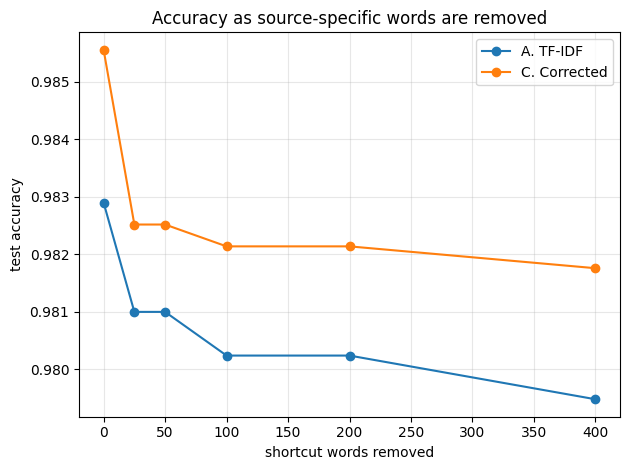

model          A. TF-IDF  C. Corrected
words_removed                         
0                 0.9829        0.9856
25                0.9810        0.9825
50                0.9810        0.9825
100               0.9802        0.9821
200               0.9802        0.9821
400               0.9795        0.9818


In [17]:
rows = []
for n in [0, 25, 50, 100, 200, 400]:
    ws = SHORT.head(n).word.tolist()
    texts = list(map(str, X_test)) if n == 0 else strip(X_test, ws)
    for model, fn in [("A. TF-IDF", prob_a), ("C. Corrected", prob_c)]:
        yp = (fn(texts) >= .5).astype(int)
        rows.append({"model": model, "words_removed": n, "accuracy": accuracy_score(y_test, yp)})
CURVE = pd.DataFrame(rows)
for m, g in CURVE.groupby("model"):
    plt.plot(g.words_removed, g.accuracy, "o-", label=m)
plt.xlabel("shortcut words removed"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.title("Accuracy as source-specific words are removed")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "shortcut_curve.png"), dpi=200); plt.show()
print(CURVE.pivot(index="words_removed", columns="model", values="accuracy").round(4))

## Step 9: Do A and C rely on the same words?

In [11]:
def content_top(pairs, k=10):
    ws = [w for w, _ in pairs if w not in ENGLISH_STOP_WORDS and len(w) > 2 and " " not in w]
    return set(ws[:k])

rows = []
for r in RESULTS:
    a_pairs = sorted(((w, s) for w, s in zip(r["A"]["words"], r["A"]["scores"])), key=lambda t: -abs(t[1]))
    a_set = content_top(list(dict(a_pairs).items()))
    c_set = content_top(top_words(r["C"]["words"], r["C"]["scores"], k=50))
    if a_set and c_set:
        rows.append({"idx": r["idx"], "label": r["label"], "jaccard": len(a_set & c_set) / len(a_set | c_set),
                     "shared": ", ".join(sorted(a_set & c_set))})
AGREE = pd.DataFrame(rows)
print(f"Average overlap of top-10 words (Jaccard, 0 = none, 1 = identical): {AGREE.jaccard.mean():.2f}")
print(AGREE.head(10).to_string(index=False))
AGREE.to_csv(os.path.join(OUT, "A_vs_C_agreement.csv"), index=False)

Average overlap of top-10 words (Jaccard, 0 = none, 1 = identical): 0.19
 idx  label  jaccard                              shared
1981      1 0.176471                 link, prices, rolex
1863      1 0.176471      hello, leading, pharmaceutical
 541      1 0.176471               prices, product, site
2547      1 0.250000 business, free, hundreds, questions
2202      1 0.333333          grow, hey, use, watch, www
1976      1 0.111111                         free, reply
 345      1 0.176471       books, linguistics, linguists
 238      1 0.111111                     investment, url
1666      1 0.000000                                    
1330      1 0.111111                        course, info


## Step 10: Try your own emails

In [12]:
def explain_both(text, title="custom"):
    a, c = explain_a(text), ig_explain(text)
    part = highlight(a["words"], a["scores"], f"{title} | Model A p(phish)={a['prob']:.3f}") + \
           highlight(c["words"], c["scores"], f"{title} | Model C p(phish)={c['prob']:.3f}")
    HTML_PARTS.append(part); display(HTML(part))
    return a, c

CASES = [
    "Your account has been suspended. Verify your password within 24 hours at the link below or lose access.",
    "Congratulations! You won a $1000 gift card. Click here and enter your bank details to claim your prize.",
    "Hi team, the project meeting is moved to Thursday 3 pm. Please bring the updated slides.",
    "Thanks for sending the report. I made a few comments on section 2, let me know what you think.",
]
for k, t in enumerate(CASES):
    explain_both(t, f"case {k + 1}")
# Add your own: explain_both("paste an email here")

## Step 11: Save and download

In [15]:
with open(os.path.join(OUT, "explanations.html"), "w") as f:
    f.write("<html><body>" + "".join(HTML_PARTS) + "</body></html>")
pd.DataFrame([{"idx": r["idx"], "label": r["label"], "A_prob": r["A"]["prob"], "C_prob": r["C"]["prob"],
               "C_ig_gap": r["C"]["gap"],
               "A_top": "; ".join(f"{w}:{s:+.3f}" for w, s in r["A"]["top"][:5]),
               "C_top": "; ".join(f"{w}:{s:+.3f}" for w, s in top_words(r["C"]["words"], r["C"]["scores"], 5))}
              for r in RESULTS]).to_csv(os.path.join(OUT, "sample_explanations.csv"), index=False)

print("Saved to", OUT)
print(sorted(os.listdir(OUT)))
print("Open explanations.html in a browser to screenshot the highlights.")

Saved to s:\ML-CAPSTONE\xai_outputs
['A_vs_C_agreement.csv', 'deletion_test.csv', 'deletion_test.png', 'example_A_phish.png', 'example_C_phish.png', 'explanations.html', 'global_A.png', 'global_A_top_words.csv', 'global_C_words.csv', 'ig_completeness.csv', 'one_class_words.csv', 'sample_explanations.csv']
Open explanations.html in a browser to screenshot the highlights.


## How to read the results

| Result | Good sign | Warning sign |
|---|---|---|
| IG completeness gap | Under about 5% | Over 20%: raise `IG_STEPS` |
| Deletion test | Top-5 drop much larger than random-5 | Similar drops: the highlight is not faithful |
| Shortcut check | Top words are phishing cues ("verify", "account", "click") | Top safe words are names or company terms: the model learned the email source |
| A vs C overlap | Some overlap: both found real cues | High overlap plus shortcut words: both learned the same dataset artefact |

**Slide line:** "Explainability shows which words drive each decision, checks that the explanation is faithful (deletion test), and tests whether the models learned phishing cues or dataset shortcuts."

In [18]:
# ===== Dataset audit: exact counts for Slide 3 =====
import re, json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

CSV = r"phishing_artifacts\Phishing_Email.csv"     # change if needed
SEED = 42

DF = pd.read_csv(CSV)
TEXT = [c for c in DF.columns if "text" in c.lower()][0]
LAB  = [c for c in DF.columns if "type" in c.lower() or "label" in c.lower()][0]
R = {"columns": list(DF.columns), "raw_rows": len(DF)}

# 1) Missing and empty bodies
R["null_text"] = int(DF[TEXT].isna().sum())
R["null_label"] = int(DF[LAB].isna().sum())
df = DF.dropna(subset=[TEXT]).copy()
df[TEXT] = df[TEXT].astype(str)
empty_mask = df[TEXT].str.strip().str.lower().isin(["", "empty", "nan", "none"])
R["empty_or_placeholder"] = int(empty_mask.sum())
R["empty_breakdown"] = df.loc[empty_mask, TEXT].str.strip().str.lower().replace("", "<blank>").value_counts().to_dict()
df = df[~empty_mask]
df["label"] = df[LAB].apply(lambda v: 1 if "phish" in str(v).lower() else 0)
R["after_empty_removal"] = len(df)

# 2) Exact duplicates
dup_all = df.duplicated(subset=[TEXT], keep=False)
R["exact_duplicate_rows_removed"] = int(df.duplicated(subset=[TEXT]).sum())
R["emails_involved_in_duplicates"] = int(dup_all.sum())
g = df[dup_all].groupby(TEXT)["label"].nunique()
R["duplicate_texts_with_conflicting_labels"] = int((g > 1).sum())
R["duplicates_by_class"] = df[df.duplicated(subset=[TEXT])]["label"].map({1: "phishing", 0: "safe"}).value_counts().to_dict()
df = df.drop_duplicates(subset=[TEXT]).reset_index(drop=True)
R["final_rows"] = len(df)
R["final_class_counts"] = df["label"].map({1: "phishing", 0: "safe"}).value_counts().to_dict()
R["final_phishing_pct"] = round(100 * df["label"].mean(), 2)

# 3) Split (same as training notebook)
X, y = df[TEXT].values, df["label"].values
Xtmp, Xte, ytmp, yte = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
Xtr, Xva, ytr, yva = train_test_split(Xtmp, ytmp, test_size=0.15 / 0.85, stratify=ytmp, random_state=SEED)
R["split_sizes"] = {"train": len(Xtr), "val": len(Xva), "test": len(Xte)}

# 4) Email length and 128-token truncation (approx. by words)
words = df[TEXT].str.split().str.len()
R["words_median"] = int(words.median()); R["words_p90"] = int(words.quantile(.9))
R["pct_over_128_words"] = round(100 * (words > 128).mean(), 1)

# 5) Near duplicates (TF-IDF cosine similarity)
vec = TfidfVectorizer(min_df=2, max_features=100000, sublinear_tf=True)
M = vec.fit_transform(df[TEXT].values)
def max_sim_rows(A, B, same=False):
    out = np.zeros(A.shape[0])
    for i in range(0, A.shape[0], 1000):
        S = (A[i:i + 1000] @ B.T).toarray()
        if same:
            for k in range(S.shape[0]): S[k, i + k] = 0          # ignore self
        out[i:i + 1000] = S.max(1)
    return out
ms = max_sim_rows(M, M, same=True)
R["near_dup_within_dataset"] = {f">={t}": int((ms >= t).sum()) for t in (0.8, 0.9, 0.95)}
Mtr, Mte = vec.transform(Xtr), vec.transform(Xte)
mt = max_sim_rows(Mte, Mtr)
R["test_emails_near_dup_of_train"] = {f">={t}": int((mt >= t).sum()) for t in (0.8, 0.9, 0.95)}

# 6) Source patterns
PATTERNS = {
    "Enron (enron, ect, hou, kaminski, vince)": r"\b(enron|ect|hou|kaminski|vince)\b",
    "Linguistics list (linguist*, syntax, semantics)": r"\b(linguist\w*|syntax|semantics|phonolog\w*)\b",
    "Linux / SpamAssassin lists (redhat, freshrpms, spamassassin, exmh)": r"\b(redhat|freshrpms|spamassassin|exmh|newsisfree)\b",
    "Reply / forward markers (wrote:, original message, forwarded by)": r"(\bwrote:|original message|forwarded by)",
    "Starts with 'Subject:'": r"^\s*subject\s*:",
    "Contains a URL (http / www)": r"(https?://|www\.)",
}
rows = []
for name, pat in PATTERNS.items():
    hit = df[TEXT].str.contains(pat, case=False, regex=True)
    ph, sf = int(hit[df.label == 1].sum()), int(hit[df.label == 0].sum())
    rows.append({"pattern": name, "phishing_emails": ph, "safe_emails": sf,
                 "pct_of_phishing": round(100 * ph / (df.label == 1).sum(), 1),
                 "pct_of_safe": round(100 * sf / (df.label == 0).sum(), 1)})
SRC = pd.DataFrame(rows)

print(json.dumps(R, indent=2))
print("\nSource patterns:")
print(SRC.to_string(index=False))
json.dump({"summary": R, "source_patterns": rows}, open("dataset_audit.json", "w"), indent=2)
SRC.to_csv("dataset_source_patterns.csv", index=False)
print("\nSaved dataset_audit.json and dataset_source_patterns.csv")

{
  "columns": [
    "Unnamed: 0",
    "Email Text",
    "Email Type"
  ],
  "raw_rows": 18650,
  "null_text": 16,
  "null_label": 0,
  "empty_or_placeholder": 536,
  "empty_breakdown": {
    "empty": 533,
    "<blank>": 3
  },
  "after_empty_removal": 18098,
  "exact_duplicate_rows_removed": 563,
  "emails_involved_in_duplicates": 1036,
  "duplicate_texts_with_conflicting_labels": 0,
  "duplicates_by_class": {
    "phishing": 418,
    "safe": 145
  },
  "final_rows": 17535,
  "final_class_counts": {
    "safe": 10979,
    "phishing": 6556
  },
  "final_phishing_pct": 37.39,
  "split_sizes": {
    "train": 12273,
    "val": 2631,
    "test": 2631
  },
  "words_median": 167,
  "words_p90": 746,
  "pct_over_128_words": 59.4,
  "near_dup_within_dataset": {
    ">=0.8": 4138,
    ">=0.9": 2659,
    ">=0.95": 1708
  },
  "test_emails_near_dup_of_train": {
    ">=0.8": 521,
    ">=0.9": 323,
    ">=0.95": 201
  }
}

Source patterns:
                                                           